# Global AgriCLIP Guided SAM2

This notebook implements the proposed thesis pipeline:

Image
→ DINO feature extraction
→ Global AgriCLIP representation
→ Attention map
→ Candidate mask
→ AutoBox + positive points
→ Fine-tuned SAM2
→ Segmentation

In [115]:
import os
import sys
from pathlib import Path

import cv2
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn.functional as F

from datasets import load_dataset
from PIL import Image

from sklearn.metrics.pairwise import cosine_similarity

from transformers import (
    Sam2Processor,
    Sam2Model
)

print("Libraries loaded.")

Libraries loaded.


In [116]:
device = torch.device(

    "cuda"

    if torch.cuda.is_available()

    else

    "cpu"

)

print(device)

cuda


In [117]:
#Paths registry 
PROJECT_ROOT = Path("/home/zahranadeem/thesis")

MODEL_NAME = "facebook/sam2-hiera-large"

###############################################

AGRICLIP_ROOT = (
    PROJECT_ROOT
    / "agriclip_sam2"
    / "AgriCLIP"
)

ALIGNMENT_DIR = (
    AGRICLIP_ROOT
    / "AgriCLIP_alignment"
)

ALIGNER_PATH = (
    PROJECT_ROOT
    / "vegann_aligner.pth"
)

SAM2_CHECKPOINT = (
    PROJECT_ROOT
    / "sam2_vegann_checkpoints"
    / "best_sam2_vegann_mask_decoder.pt"
)

OUTPUT_DIR = (
    PROJECT_ROOT
    / "results"
    / "agriclip_attention_guided_sam2"
)

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

print("Project:", PROJECT_ROOT)
print("AgriCLIP:", AGRICLIP_ROOT)
print("Aligner:", ALIGNER_PATH)
print("SAM2:", SAM2_CHECKPOINT)

Project: /home/zahranadeem/thesis
AgriCLIP: /home/zahranadeem/thesis/agriclip_sam2/AgriCLIP
Aligner: /home/zahranadeem/thesis/vegann_aligner.pth
SAM2: /home/zahranadeem/thesis/sam2_vegann_checkpoints/best_sam2_vegann_mask_decoder.pt


In [118]:
assert AGRICLIP_ROOT.exists()

assert ALIGNMENT_DIR.exists()

assert ALIGNER_PATH.exists()

assert SAM2_CHECKPOINT.exists()

print("Paths verified.")

Paths verified.


In [119]:
sys.path.append(str(ALIGNMENT_DIR))

from TextToConcept import TextToConcept
from LinearAligner import LinearAligner

print("AgriCLIP modules loaded.")

AgriCLIP modules loaded.


In [120]:
#Load VegAnn 
vegann = load_dataset(
    "simonMadec/VegAnn"
)

split = vegann["train"].train_test_split(

    test_size=0.20,

    seed=42

)

train_hf = split["train"]

val_hf = split["test"]

print(len(train_hf))

print(len(val_hf))

3020
755


In [121]:
sample = val_hf[12]

IMAGE_KEY = None
MASK_KEY = None

for key, value in sample.items():

    if isinstance(value, Image.Image):

        arr = np.array(value)

        if arr.ndim == 3:
            IMAGE_KEY = key

        elif arr.ndim == 2:
            MASK_KEY = key

print("Image key :", IMAGE_KEY)
print("Mask key  :", MASK_KEY)

Image key : image
Mask key  : mask


In [122]:
from PIL import Image
import numpy as np

IMAGE_KEY = "image"
MASK_KEY = "mask"


def get_image(index, split=val_hf):

    sample = split[index]

    image = sample[IMAGE_KEY]

    if isinstance(image, Image.Image):
        image = np.array(image)

    return image


def get_mask(index, split=val_hf):

    sample = split[index]

    mask = sample[MASK_KEY]

    if isinstance(mask, Image.Image):
        mask = np.array(mask)

    return mask

In [123]:
dino_model = torch.hub.load(

    "facebookresearch/dino:main",

    "dino_resnet50",

    pretrained=True

)

dino_model = dino_model.to(device)

dino_model.eval()

for p in dino_model.parameters():

    p.requires_grad = False

print("DINO loaded.")

DINO loaded.


Using cache found in /home/zahranadeem/.cache/torch/hub/facebookresearch_dino_main


In [124]:
dino_model = torch.hub.load(

    "facebookresearch/dino:main",

    "dino_resnet50",

    pretrained=True

)

dino_model = dino_model.to(device)

dino_model.eval()

for p in dino_model.parameters():

    p.requires_grad = False

print("DINO loaded.")

DINO loaded.


Using cache found in /home/zahranadeem/.cache/torch/hub/facebookresearch_dino_main


In [125]:
processor = Sam2Processor.from_pretrained(

    MODEL_NAME

)

sam2 = Sam2Model.from_pretrained(

    MODEL_NAME

)

checkpoint = torch.load(

    SAM2_CHECKPOINT,

    map_location=device

)

sam2.mask_decoder.load_state_dict(

    checkpoint["mask_decoder_state_dict"]

)

sam2 = sam2.to(device)

sam2.eval()

print("Fine-tuned SAM2 loaded.")

[transformers] You are using a model of type `sam2_video` to instantiate a model of type `sam2`. This may be expected if you are loading a checkpoint that shares a subset of the architecture (e.g., loading a `sam2_video` checkpoint into `Sam2Model`), but is otherwise not supported and can yield errors. Please verify that the checkpoint is compatible with the model you are instantiating.


Loading weights:   0%|          | 0/741 [00:00<?, ?it/s]

Fine-tuned SAM2 loaded.


In [126]:
print(val_hf[0].keys())

dict_keys(['image', 'mask', 'System', 'Orientation', 'latitude', 'longitude', 'date', 'LocAcc', 'Species', 'Owner', 'Dataset-Name', 'TVT-split1', 'TVT-split2', 'TVT-split3', 'TVT-split4', 'TVT-split5'])


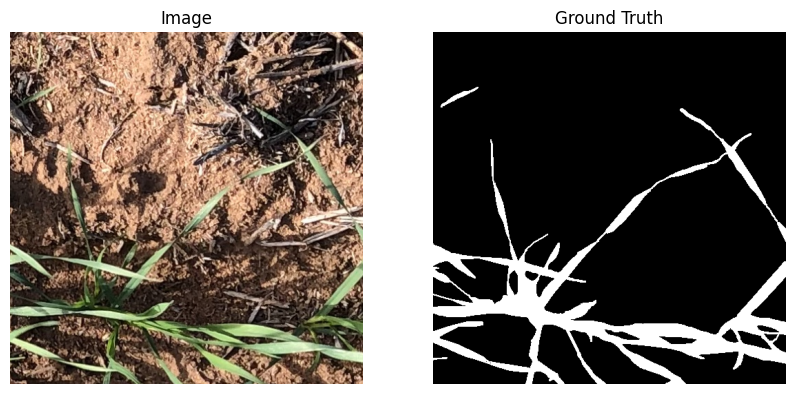

In [127]:
sample_index = 12

sample_image = get_image(

    sample_index,

    val_hf

)

gt_mask = get_mask(

    sample_index,

    val_hf

)

plt.figure(figsize=(10,5))

plt.subplot(1,2,1)

plt.imshow(sample_image)

plt.title("Image")

plt.axis("off")

plt.subplot(1,2,2)

plt.imshow(

    gt_mask,

    cmap="gray"

)

plt.title("Ground Truth")

plt.axis("off")

plt.show()

## Extract DINO Feature Map

We extract the last convolutional feature map from DINO ResNet50.

Feature map size:

7 × 7 × 2048

These local descriptors will later be compared with the global AgriCLIP representation.

In [128]:
#Regiater the feature hook 
feature_map = None

def hook_fn(module, input, output):

    global feature_map

    feature_map = output

hook = dino_model.layer4.register_forward_hook(
    hook_fn
)

print("Hook registered.")

Hook registered.


In [129]:
#Forward the image through DINO 
sample_index = 12

sample_image = get_image(
    sample_index,
    val_hf
)

image_rgb = sample_image.astype(np.float32) / 255.0

image_tensor = torch.from_numpy(
    image_rgb
).permute(
    2,
    0,
    1
).unsqueeze(
    0
).to(device)

with torch.no_grad():

    _ = dino_model(image_tensor)

print(feature_map.shape)

torch.Size([1, 2048, 16, 16])


In [130]:
#Visualize feature dimensions 
print("Channels :", feature_map.shape[1])

print("Height   :", feature_map.shape[2])

print("Width    :", feature_map.shape[3])

H = feature_map.shape[2]
W = feature_map.shape[3]

print(H, W)


Channels : 2048
Height   : 16
Width    : 16
16 16


In [131]:
#Convert feature map into 256 x 2048
H = feature_map.shape[2]
W = feature_map.shape[3]

patch_features = (

    feature_map
    .squeeze(0)
    .permute(1,2,0)
    .reshape(H * W, 2048)

)

print("Feature map:", H, "x", W)
print("Patch features:", patch_features.shape)

Feature map: 16 x 16
Patch features: torch.Size([256, 2048])


In [132]:
#Global descriptor 16x16x2048 -> 2048
global_feature = F.adaptive_avg_pool2d(

    feature_map,

    output_size=(1,1)

).reshape(-1)

print(global_feature.shape)

torch.Size([2048])


In [133]:
print("text_to_concept" in globals())
print("aligner" in globals())

True
True


In [134]:
text_to_concept = TextToConcept(
    dino_model,
    "dino_resnet50"
)

text_to_concept.load_linear_aligner(
    str(ALIGNER_PATH)
)

aligner = text_to_concept.linear_aligner

print("Aligner loaded successfully.")

Aligner loaded successfully.


In [135]:
global_feature_np = (

    global_feature

    .cpu()

    .numpy()

)

global_feature_np = global_feature_np.reshape(

    1,

    -1

)

global_aligned = aligner.get_aligned_representation(

    torch.from_numpy(

        global_feature_np

    ).float().to(device)

)

global_aligned = F.normalize(

    global_aligned,

    dim=1

)

print(global_aligned.shape)

torch.Size([1, 512])


## Encode vegetation prompts

Instead of aligning every patch independently, we encode vegetation prompts once to obtain a global semantic vegetation representation.

In [136]:
#Prompts 
POSITIVE_PROMPTS = [

    "A crop field populated by healthy plants, captured from a nadir view using a handheld camera.",

    "An agricultural scene showing healthy crops growing in the field, captured from a nadir view using a handheld camera.",

    "A field image containing healthy crop vegetation, captured from a nadir view using a handheld camera.",

    "An aerial agricultural image of dense green crop plants, captured from a nadir view using a handheld camera.",

    "Healthy crop canopy covering the field, captured from a nadir view using a handheld camera.",

    "Agricultural vegetation viewed from above, captured from a nadir view using a handheld camera."

]
NEGATIVE_PROMPTS = [

    "Bare agricultural soil, captured from a nadir view using a handheld camera.",

    "An empty agricultural field without vegetation, captured from a nadir view using a handheld camera.",

    "Dry exposed soil, captured from a nadir view using a handheld camera.",

    "Agricultural land without crops, captured from a nadir view using a handheld camera.",

    "Only background soil visible, captured from a nadir view using a handheld camera.",

    "A field without vegetation, captured from a nadir view using a handheld camera."

]


In [137]:
positive_embeddings = []

for prompt in POSITIVE_PROMPTS:

    embedding = text_to_concept.encode_text(

        [[prompt]]

    )

    positive_embeddings.append(

        embedding.squeeze()

    )

positive_embeddings = torch.stack(

    positive_embeddings

)

positive_embedding = positive_embeddings.mean(

    dim=0

)

positive_embedding = F.normalize(

    positive_embedding,

    dim=0

)

print(positive_embedding.shape)

torch.Size([512])


Generated 16x16 Attention Map Matrix.
Attention Minimum Value Range: 0.40290963649749756
Attention Maximum Value Range: 0.7935186624526978


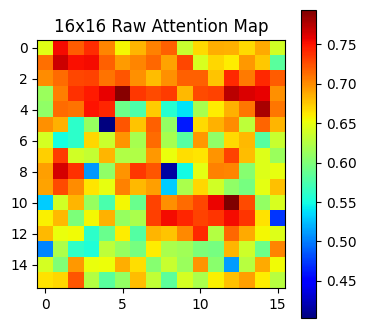

In [138]:
# ==========================================
# CELL 5: COMPUTE ATTENTION (LOCAL DESCRIPTORS vs GLOBAL ALIGNED)
# ==========================================
# Normalize local patches across channel space
local_features_normalized = F.normalize(patch_features, dim=1) # Shape: (256, 2048)

# Project local patch descriptors into the 512-dimension concept space using the Aligner weight matrix
local_aligned = aligner.get_aligned_representation(local_features_normalized.float().to(device))
local_aligned = F.normalize(local_aligned, dim=1) # Shape: (256, 512)

# Compute cosine similarity between each of the 256 local patches and the single global scene descriptor
# Matrix multiplication returns the 256 localized attention weights
attention_scores = torch.matmul(local_aligned, global_aligned.T).squeeze() # Shape: (256,)

# Reshape explicitly back into a 2D matrix structure matching the 16x16 grid
attention_map_16x16 = attention_scores.view(16, 16)

print("Generated 16x16 Attention Map Matrix.")
print("Attention Minimum Value Range:", attention_map_16x16.min().item())
print("Attention Maximum Value Range:", attention_map_16x16.max().item())

plt.figure(figsize=(4, 4))
plt.imshow(attention_map_16x16.cpu().numpy(), cmap="jet")
plt.colorbar()
plt.title("16x16 Raw Attention Map")
plt.show()


In [139]:
# ==========================================
# CELL 6: UPSAMPLE, SMOOTH & OTSU THRESHOLD
# ==========================================
# Fetch image spatial constraints

"""H_img, W_img = sample_image.shape[:2]

# 1. Explicitly upscale the attention map to original dimensions without using .squeeze()
attention_4d = attention_map_16x16.view(1, 1, 16, 16)
attention_up = F.interpolate(
    attention_4d,
    size=(H_img, W_img),
    mode="bilinear",
    align_corners=False
)
attention_np = attention_up.cpu().numpy() # Extract the safe 2D array [H, W]

# 2. Normalize the map cleanly between 0.0 and 1.0
attn_min = attention_np.min()
attn_max = attention_np.max()
if (attn_max - attn_min) > 1e-8:
    attention_normalized = (attention_np - attn_min) / (attn_max - attn_min)
else:
    attention_normalized = np.zeros_like(attention_np)

# 3. Apply Gaussian Smoothing to blend patch transitions seamlessly
# Kernel scale (15,15) works perfectly for higher-resolution attention sources
attention_smoothed = cv2.GaussianBlur(attention_normalized, (15, 15), 0)


# 4. Apply Otsu Binarization to automatically isolate the threshold gap
attention_uint8 = (attention_smoothed * 255).astype(np.uint8)
_, candidate_mask = cv2.threshold(
    attention_uint8, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU
)
candidate_mask = (candidate_mask > 0).astype(np.uint8)

print(f"Mask Isolation Complete. Total Active Mask Foreground Pixels: {np.sum(candidate_mask)}")"""

# ==========================================
# CELL 6
## ==========================================
# UPSAMPLE
# ==========================================

H_img, W_img = sample_image.shape[:2]

attention_up = F.interpolate(

    attention_map_16x16.view(1,1,16,16),

    size=(H_img,W_img),

    mode="bilinear",

    align_corners=False

)

attention_np = attention_up.squeeze().cpu().numpy()

attention_np = (

    attention_np-attention_np.min()

)/(

    attention_np.max()-attention_np.min()+1e-8

)

In [154]:
num_labels, labels, stats, _ = cv2.connectedComponentsWithStats(
    candidate_mask.astype(np.uint8),
    connectivity=8
)

clean = np.zeros_like(candidate_mask)

for label in range(1, num_labels):

    component = (labels == label)

    ys, xs = np.where(component)

    # Skip components touching image border
    if (
        xs.min() == 0 or
        ys.min() == 0 or
        xs.max() == candidate_mask.shape[1] - 1 or
        ys.max() == candidate_mask.shape[0] - 1
    ):
        continue

    clean[component] = 1

candidate_mask = clean

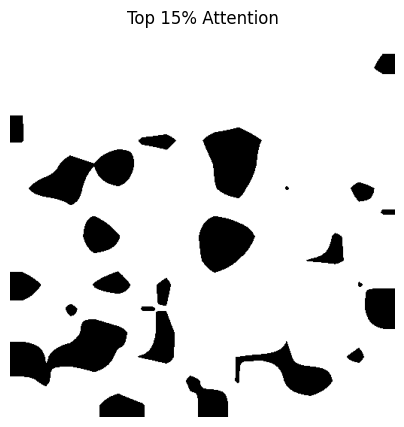

In [155]:
# keep only strongest 15%

threshold = np.percentile(

    attention_np,

    15

)

candidate_mask = (

    attention_np >= threshold

).astype(np.uint8)

plt.figure(figsize=(5,5))

plt.imshow(candidate_mask,cmap="gray")

plt.title("Top 15% Attention")

plt.axis("off")

plt.show()

In [156]:
# ==========================================
# RE-ALIGNED DIAGNOSTIC PATCH GENERATOR (16x16 Grid)
# ==========================================
mask_resized = cv2.resize(
    gt_mask,
    (224, 224),
    interpolation=cv2.INTER_NEAREST
)

patch_labels = []
patch_cover = []

# Scan across the 16x16 grid using the updated 14x14 pixel layout bounds (16 * 14 = 224)
for r in range(16):
    for c in range(16):
        patch = mask_resized[
            r * 14 : (r + 1) * 14,
            c * 14 : (c + 1) * 14
        ]
        
        ratio = (patch > 127).mean()
        patch_cover.append(ratio)
        
        if ratio >= 0.10:
            patch_labels.append("Vegetation")
        else:
            patch_labels.append("Background")

print("--- 16x16 SPATIAL MAP INSPECTOR ---")
labels_np = np.array(patch_labels).reshape(16, 16)
print(f"Total Vegetation Count: {patch_labels.count('Vegetation')} / 256")
print(f"Total Background Count: {patch_labels.count('Background')} / 256")


--- 16x16 SPATIAL MAP INSPECTOR ---
Total Vegetation Count: 79 / 256
Total Background Count: 177 / 256


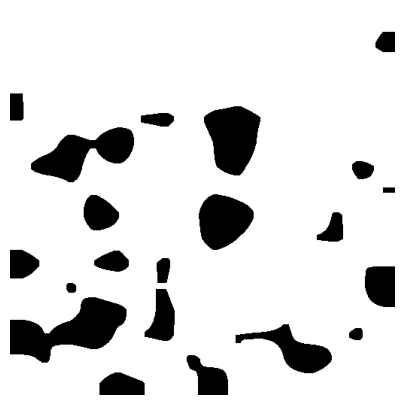

In [157]:
kernel = np.ones((7,7),np.uint8)

candidate_mask = cv2.morphologyEx(

    candidate_mask,

    cv2.MORPH_OPEN,

    kernel

)

candidate_mask = cv2.morphologyEx(

    candidate_mask,

    cv2.MORPH_CLOSE,

    kernel

)

plt.figure(figsize=(5,5))

plt.imshow(candidate_mask,cmap="gray")

plt.axis("off")

plt.show()

In [158]:
ys, xs = np.where(candidate_mask > 0)

if len(xs) == 0:

    auto_box = np.array([
        0,
        0,
        sample_image.shape[1] - 1,
        sample_image.shape[0] - 1
    ])

else:

    x0 = xs.min()
    x1 = xs.max()

    y0 = ys.min()
    y1 = ys.max()

    pad = 30

ys,xs=np.where(candidate_mask>0)

x0=max(xs.min()-30,0)
x1=min(xs.max()+30,W_img-1)

y0=max(ys.min()-30,0)
y1=min(ys.max()+30,H_img-1)

auto_box=np.array([x0,y0,x1,y1])

print(auto_box)

[  0   0 511 511]


In [159]:
#Three pos points 
from scipy.ndimage import distance_transform_edt
distance=cv2.distanceTransform(

    candidate_mask.astype(np.uint8),

    cv2.DIST_L2,

    5

)

points=[]

working=distance.copy()

for _ in range(3):

    y,x=np.unravel_index(

        np.argmax(working),

        working.shape

    )

    points.append([x,y])

    cv2.circle(

        working,

        (x,y),

        45,

        0,

        -1

    )

points=np.array(points)

labels=np.ones(3)




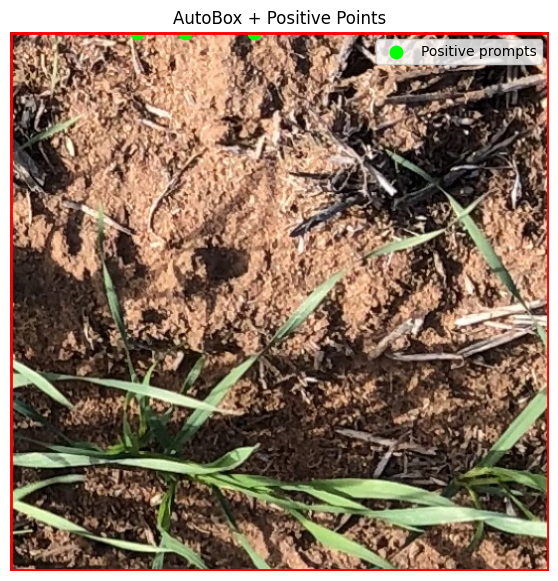

In [160]:
#Visulaize prompts 
plt.figure(figsize=(7,7))

plt.imshow(sample_image)

plt.scatter(
    points[:,0],
    points[:,1],
    c="lime",
    s=80,
    marker="o",
    label="Positive prompts"
)

x0, y0, x1, y1 = auto_box

plt.gca().add_patch(

    plt.Rectangle(

        (x0, y0),

        x1 - x0,

        y1 - y0,

        edgecolor="red",

        linewidth=2,

        fill=False

    )

)

plt.legend()

plt.title("AutoBox + Positive Points")

plt.axis("off")

plt.show()

In [161]:
print("Attention statistics")

print("Min :", attention_map_16x16.min().item())
print("Max :", attention_map_16x16.max().item())
print("Mean:", attention_map_16x16.mean().item())
print("Std :", attention_map_16x16.std().item())

Attention statistics
Min : 0.40290963649749756
Max : 0.7935186624526978
Mean: 0.6644799113273621
Std : 0.0636802539229393


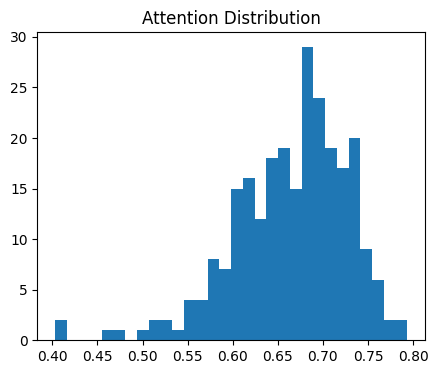

In [162]:
plt.figure(figsize=(5,4))

plt.hist(
    attention_map_16x16.cpu().numpy().flatten(),
    bins=30
)

plt.title("Attention Distribution")

plt.show()

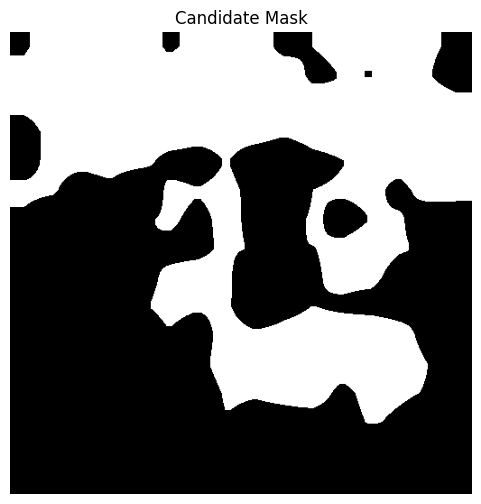

In [149]:
plt.figure(figsize=(6,6))
plt.imshow(candidate_mask, cmap="gray")
plt.title("Candidate Mask")
plt.axis("off")
plt.show()

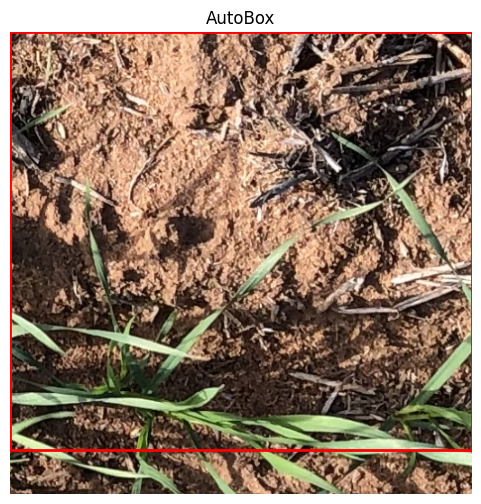

In [150]:
plt.figure(figsize=(6,6))
plt.imshow(sample_image)

x0, y0, x1, y1 = auto_box

plt.gca().add_patch(
    plt.Rectangle(
        (x0, y0),
        x1 - x0,
        y1 - y0,
        edgecolor="red",
        linewidth=2,
        fill=False
    )
)

plt.title("AutoBox")
plt.axis("off")
plt.show()